In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

1. Wczytanie danych

In [2]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Etykieta: species (3 gatunki: Adelie, Chinstrap, Gentoo) - klasyfikacja wieloklasowa.

2. EDA

In [4]:
print(df["species"].value_counts(normalize=True).round(3))
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
bill_length_mm,0.6
bill_depth_mm,0.6
flipper_length_mm,0.6
body_mass_g,0.6
sex,3.2


In [5]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [6]:
print("Średnie wymiary wg gatunku:")
print(df.groupby("species")[num_cols].mean().round(1), "\n")
print("Rozkład gatunków na wyspach (wierszami do 1):")
print(pd.crosstab(df["island"], df["species"], normalize="index").round(3), "\n")
print("Średnia masa (g) wg gatunku i płci:")
print(df.pivot_table(index="sex", columns="species", values="body_mass_g").round(1))

Średnie wymiary wg gatunku:
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0 

Rozkład gatunków na wyspach (wierszami do 1):
species    Adelie  Chinstrap  Gentoo
island                              
Biscoe      0.262      0.000   0.738
Dream       0.452      0.548   0.000
Torgersen   1.000      0.000   0.000 

Średnia masa (g) wg gatunku i płci:
species  Adelie  Chinstrap  Gentoo
sex                               
Female   3368.8     3527.2  4679.7
Male     4043.5     3939.0  5484.8


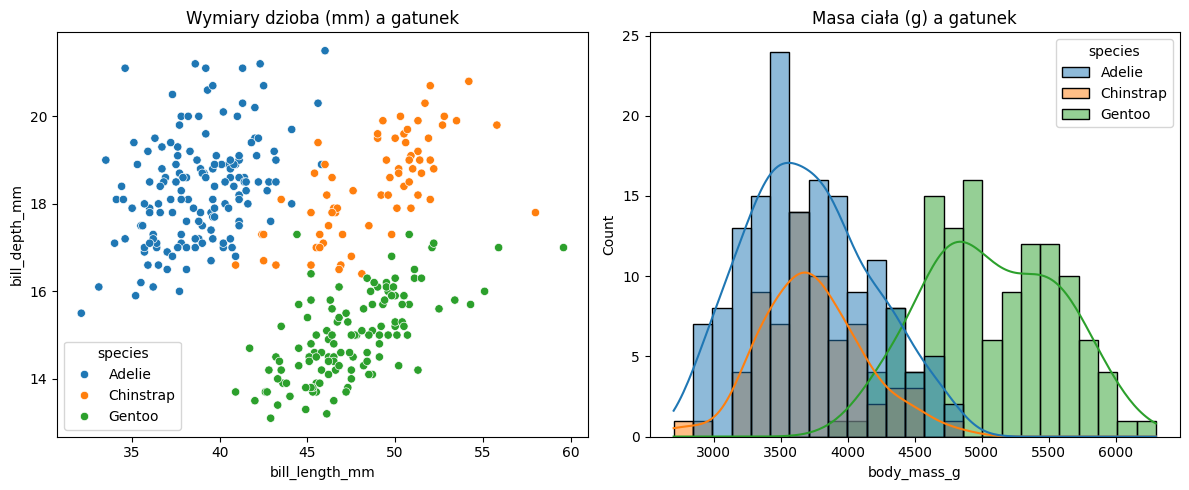

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", ax=axes[0])
axes[0].set_title("Wymiary dzioba (mm) a gatunek")
sns.histplot(data=df, x="body_mass_g", hue="species", bins=25, kde=True, ax=axes[1])
axes[1].set_title("Masa ciała (g) a gatunek")
fig.tight_layout()
plt.show()

Wnioski z EDA i decyzje:
- klasy są nieco niezbalansowane (Adelie 44.2%, Gentoo 36.0%, Chinstrap 19.8%) -> potrzebny baseline (DummyClassifier) oraz stratify przy podziale
- występują braki w pomiarach (0.6%) oraz braki w płci (3.2%) -> imputacja (SimpleImputer: mediana dla liczb, najczęstsza wartość dla kategorii)
- island i sex są zmiennymi tekstowymi -> kodowanie one-hot (OneHotEncoder)
- cechy liczbowe mają różne skale: wymiary dzioba są w mm, płetwa w mm, a masa ciała w g -> standaryzacja (StandardScaler)
- wymiary dzioba, masa ciała oraz wyspa bardzo silnie różnicują gatunki (Gentoo są znacznie cięższe i mieszkają na Biscoe, Chinstrap mają długie i głębokie dzioby i mieszkają na Dream)
- ocena kolumn i wierszy: zostawiamy wszystkie 6 cech (brak duplikatów i wycieku danych), a wiersze z brakami zostawiamy, żeby obsłużył je imputer w pipeline.


In [8]:
print(df[df["bill_length_mm"].isna()])
print("\nLista kolumn w zbiorze:", df.columns.tolist())

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
339          NaN  NaN  

Lista kolumn w zbiorze: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


3. Podział train / test

In [9]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "island", "sex"]
target = "species"
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,
    stratify=df[target],
    random_state=42,
)
print(X_train.shape, X_test.shape)
print("\nProporcje gatunków w train:\n", y_train.value_counts(normalize=True).round(3))
print("\nProporcje gatunków w test:\n", y_test.value_counts(normalize=True).round(3))

(258, 6) (86, 6)

Proporcje gatunków w train:
 species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

Proporcje gatunków w test:
 species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


4. Przygotowanie danych

4a. Braki

In [10]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[["bill_length_mm", "body_mass_g"]])
print("hiperparametr:", imputer.strategy)
print("wyuczone mediany:", imputer.statistics_)
bill_mass_test = imputer.transform(X_test[["bill_length_mm", "body_mass_g"]])
print("braki w teście po transform:", np.isnan(bill_mass_test).sum())

hiperparametr: median
wyuczone mediany: [  44.7 4062.5]
braki w teście po transform: 0


4b. Kodowanie zmiennych tekstowych

In [11]:
try:
    LogisticRegression().fit(X_train[["island"]], y_train)
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: 'Biscoe'


In [12]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train[["island"]].dropna())
print("kategorie:", encoder.categories_)
przyklad = pd.DataFrame({"island": ["Torgersen", "Biscoe", "Dream"]})
pd.DataFrame(encoder.transform(przyklad).toarray(), index=przyklad["island"],
             columns=encoder.get_feature_names_out())

kategorie: [array(['Biscoe', 'Dream', 'Torgersen'], dtype=object)]


,island_Biscoe,island_Dream,island_Torgersen
island,,,
Torgersen,0.0,0.0,1.0
Biscoe,1.0,0.0,0.0
Dream,0.0,1.0,0.0


4c. Skalowanie

In [13]:
bill_mass_train = imputer.transform(X_train[["bill_length_mm", "body_mass_g"]])
scaler = StandardScaler().fit(bill_mass_train)
print("średnie (mm, g):", scaler.mean_.round(2))
print("odchylenia (mm, g):", scaler.scale_.round(2))
bill_mass_test_s = scaler.transform(bill_mass_test)
print("pierwsze 3 wiersze testu po skalowaniu:\n", bill_mass_test_s[:3].round(2))

średnie (mm, g): [  44.12 4215.02]
odchylenia (mm, g): [  5.51 798.04]
pierwsze 3 wiersze testu po skalowaniu:
 [[-0.39 -0.08]
 [-0.59  0.55]
 [-0.48 -0.27]]


4d. Wszystko razem

In [14]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]
przygotowanie = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")),             cat_features),
])
model = make_pipeline(przygotowanie, LogisticRegression())
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression())])

5. Trenowanie

In [15]:
model.fit(X_train, y_train)
liczby = model.named_steps["columntransformer"].named_transformers_["liczby"]
print("mediany (z train):", liczby.named_steps["simpleimputer"].statistics_.round(2))
kategorie = model.named_steps["columntransformer"].named_transformers_["kategorie"]
print("najczęstsze kategorie (z train):", kategorie.named_steps["simpleimputer"].statistics_)
nazwy = model.named_steps["columntransformer"].get_feature_names_out()
clf = model.named_steps["logisticregression"]
wagi = pd.DataFrame(clf.coef_.T, index=nazwy, columns=clf.classes_)
wagi.round(3)

mediany (z train): [  44.7   17.3  197.  4062.5]
najczęstsze kategorie (z train): ['Biscoe' 'Male']


,Adelie,Chinstrap,Gentoo
liczby__bill_length_mm,-2.325,1.887,0.438
liczby__bill_depth_mm,0.984,0.339,-1.322
liczby__flipper_length_mm,-0.545,-0.302,0.847
liczby__body_mass_g,0.027,-0.766,0.738
kategorie__island_Biscoe,-0.110,-0.740,0.850
kategorie__island_Dream,-0.538,1.164,-0.626
kategorie__island_Torgersen,0.649,-0.423,-0.226
kategorie__sex_Female,-0.434,0.481,-0.048
kategorie__sex_Male,0.434,-0.480,0.046


6. Predykcja

In [16]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

podglad = X_test.head(5).copy()
for i, gatunek in enumerate(model.classes_):
    podglad[f"p({gatunek})"] = proba[:5, i].round(2)
podglad["predykcja"] = y_pred[:5]
podglad["prawda"] = y_test.head(5).values
podglad

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,p(Adelie),p(Chinstrap),p(Gentoo),predykcja,prawda
236,42.0,13.5,210.0,4150.0,Biscoe,Female,0.01,0.00,0.99,Gentoo,Gentoo
230,40.9,13.7,214.0,4650.0,Biscoe,Female,0.01,0.00,0.99,Gentoo,Gentoo
151,41.5,18.5,201.0,4000.0,Dream,Male,0.92,0.07,0.01,Adelie,Adelie
173,48.5,17.5,191.0,3400.0,Dream,Male,0.03,0.96,0.01,Chinstrap,Chinstrap
174,43.2,16.6,187.0,2900.0,Dream,Female,0.11,0.88,0.01,Chinstrap,Chinstrap


7. Ewaluacja

In [17]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
mapa_wysp = {"Biscoe": "Gentoo", "Dream": "Chinstrap", "Torgersen": "Adelie"}
regula_wyspa = (X_test["island"].map(mapa_wysp) == y_test).mean()
wyniki = pd.Series({
    "baseline (zawsze Adelie)": baseline.score(X_test, y_test),
    "prosta reguła (tylko wyspa)": regula_wyspa,
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
wyniki.round(3)

,0
baseline (zawsze Adelie),0.442
prosta reguła (tylko wyspa),0.686
pipeline – train,0.992
pipeline – test,1.000


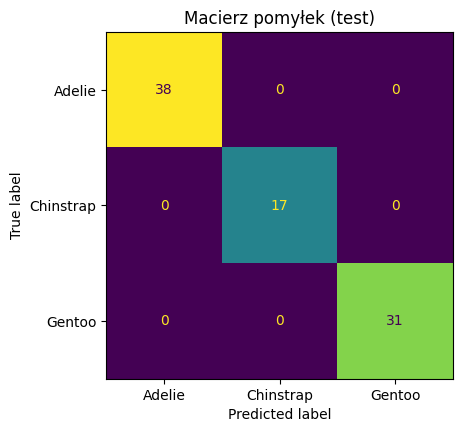

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [18]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred, labels=model.classes_),
    display_labels=model.classes_
).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (test)")
plt.show()
print(classification_report(y_test, y_pred, digits=3))

8. Iteracja

In [19]:
def zbuduj(num, cat, add_indicator=False, scale=True):
    num_steps = [SimpleImputer(strategy="median", add_indicator=add_indicator)]
    if scale:
        num_steps.append(StandardScaler())
    transformers = [("liczby", make_pipeline(*num_steps), num)]
    if cat:
        transformers.append(
            ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                        OneHotEncoder(handle_unknown="ignore")), cat)
        )
    przyg = ColumnTransformer(transformers)
    return make_pipeline(przyg, LogisticRegression(max_iter=1000))
warianty = {
    "pełny": zbuduj(num_features, cat_features),
    "+ flaga braków": zbuduj(num_features, cat_features, add_indicator=True),
    "bez płci": zbuduj(num_features, ["island"]),
    "bez wyspy (tylko pomiary i płeć)": zbuduj(num_features, ["sex"]),
    "tylko dziób i masa (mm + g)": zbuduj(["bill_length_mm", "bill_depth_mm", "body_mass_g"], []),
}
pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

,0
pełny,1.0
+ flaga braków,1.0
bez płci,1.0
bez wyspy (tylko pomiary i płeć),1.0
tylko dziób i masa (mm + g),1.0


Wniosek z iteracji: w przeciwieństwie do Titanica, gdzie usunięcie płci mocno obniżało wynik, u pingwinów same cechy anatomiczne (wymiary dzioba w mm i masa ciała w g po standaryzacji) wystarczają do bezbłędnego rozróżnienia wszystkich 3 gatunków w zbiorze testowym, nawet bez informacji o płci i wyspie.